In [1]:
import tensorflow as tf

MODEL_PATH = "/kaggle/input/models/rahifrahif/deepfake-img-detection/pytorch/default/1/best_deepfake_detector.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Deepfake model loaded successfully!")
model.summary()

I0000 00:00:1792297846.695456      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792297846.699244      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Deepfake model loaded successfully!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,021,864 (30.60 MB)

 Trainable params: 1,822,049 (6.95 MB)

 Non-trainable params: 2,555,715 (9.75 MB)

 Optimizer params: 3,644,100 (13.90 MB)

Raw score : 0.787701
Result    : FAKE  (Confidence: 78.77%)


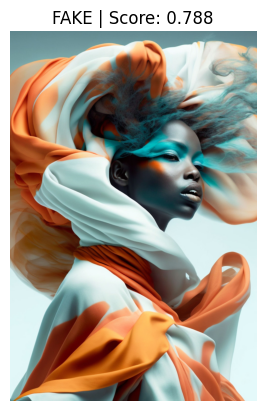

In [3]:
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.efficientnet import preprocess_input
import matplotlib.pyplot as plt

img_path = "/kaggle/input/datasets/saurabhbagchi/deepfake-image-detection/test-20250112T065939Z-001/test/fake/10.jpg"

# ২. Img load and Preprocessing
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

img_array = preprocess_input(img_array)

# 3. Prediction
prediction = model.predict(img_array, verbose=0)
score = float(prediction[0][0])

print(f"Raw score : {score:.6f}")

if score > 0.5:
    print(f"Result    : FAKE  (Confidence: {score*100:.2f}%)")
else:
    print(f"Result    : REAL  (Confidence: {(1-score)*100:.2f}%)")

# Img Show
plt.imshow(image.load_img(img_path))
plt.title(f"{'FAKE' if score > 0.5 else 'REAL'} | Score: {score:.3f}")
plt.axis("off")
plt.show()

Raw score : 0.162714
Result    : REAL  (Confidence: 83.73%)


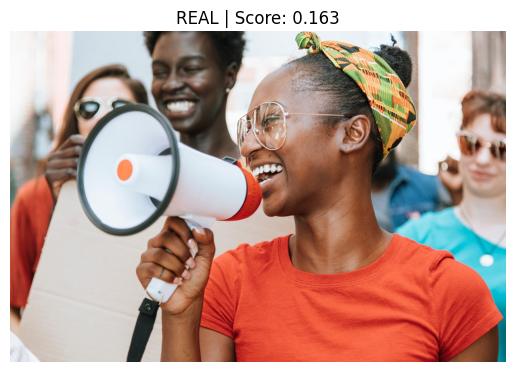

In [7]:
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.efficientnet import preprocess_input
import matplotlib.pyplot as plt

img_path = "/kaggle/input/datasets/saurabhbagchi/deepfake-image-detection/test-20250112T065939Z-001/test/real/5004.jpg"

# ২. Img load and Preprocessing
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

img_array = preprocess_input(img_array)

# 3. Prediction
prediction = model.predict(img_array, verbose=0)
score = float(prediction[0][0])

print(f"Raw score : {score:.6f}")

if score > 0.5:
    print(f"Result    : FAKE  (Confidence: {score*100:.2f}%)")
else:
    print(f"Result    : REAL  (Confidence: {(1-score)*100:.2f}%)")

# Img Show
plt.imshow(image.load_img(img_path))
plt.title(f"{'FAKE' if score > 0.5 else 'REAL'} | Score: {score:.3f}")
plt.axis("off")
plt.show()